# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [1]:
# Importy i ustawienia
import copy
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)                     # ziarno losowości: te same wagi startowe i kolejność danych
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
KLASY = ["bazofil", "eozynofil", "erytroblast", "niedojrz. granulocyt", "limfocyt", "monocyt", "neutrofil", "płytka krwi"]

In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

train (11959, 28, 28, 3), uint8, wartości 0 do 255
val   (1712, 28, 28, 3), uint8, wartości 0 do 255
test  (3421, 28, 28, 3), uint8, wartości 0 do 255
                      train  val  test
bazofil                 852  122   244
eozynofil              2181  312   624
erytroblast            1085  155   311
niedojrz. granulocyt   2026  290   579
limfocyt                849  122   243
monocyt                 993  143   284
neutrofil              2330  333   666
płytka krwi            1643  235   470


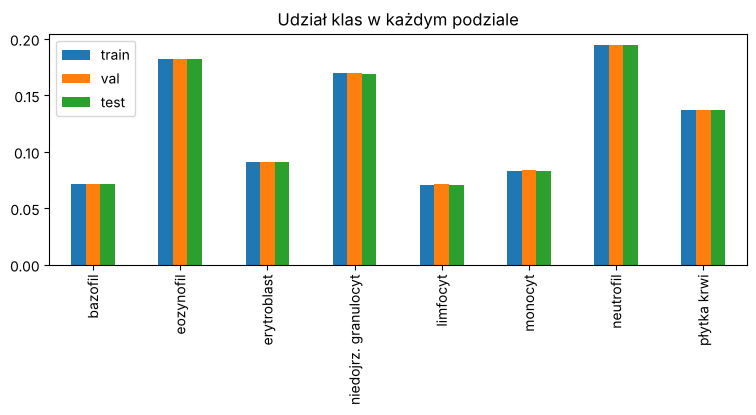

puste obrazy w train: 0
duplikaty w train: 8
te same obrazy w train i val: 3
te same obrazy w train i test: 5
te same obrazy w val i test: 1


In [3]:
# A1. Struktura, liczebność klas i jakość danych
obrazy = {s: data[f"{s}_images"] for s in ["train", "val", "test"]}
etykiety = {s: data[f"{s}_labels"].ravel() for s in ["train", "val", "test"]}   # ravel: (N, 1) na (N,)
for s in obrazy:
    print(f"{s:5s} {obrazy[s].shape}, {obrazy[s].dtype}, wartości {obrazy[s].min()} do {obrazy[s].max()}")
# (N, 28, 28, 3): N obrazów 28 x 28 pikseli, 3 kanały kolorów R, G, B, liczby 0 do 255.

liczebnosc = pd.DataFrame({s: np.bincount(etykiety[s]) for s in etykiety}, index=KLASY)
print(liczebnosc)
(liczebnosc / liczebnosc.sum()).plot(kind="bar", figsize=(9, 3), title="Udział klas w każdym podziale")
plt.show()

# Jakość: puste obrazy i identyczne obrazy (porównanie "odcisków palca" MD5 z bajtów obrazu).
hashe = {s: [hashlib.md5(o.tobytes()).hexdigest() for o in obrazy[s]] for s in obrazy}
print("puste obrazy w train:", sum(o.std() == 0 for o in obrazy["train"]))
print("duplikaty w train:", len(hashe["train"]) - len(set(hashe["train"])))
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"te same obrazy w {a} i {b}:", len(set(hashe[a]) & set(hashe[b])))

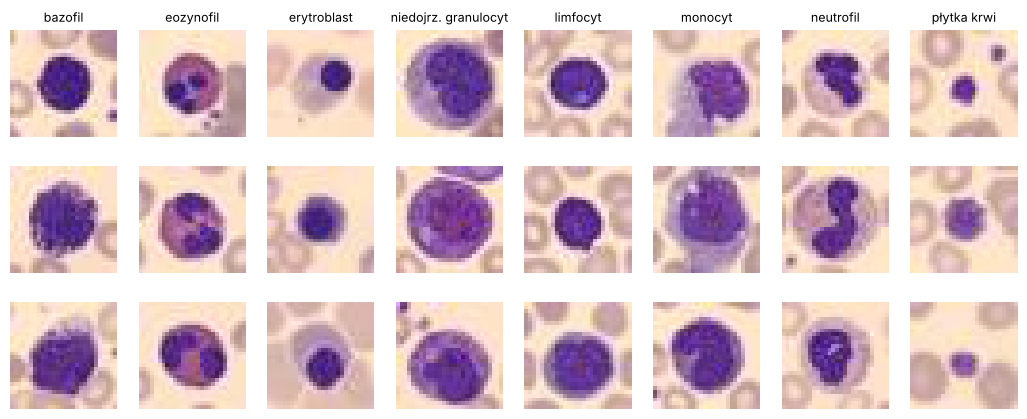

In [4]:
# A2. Przykładowe obrazy każdej klasy
fig, axes = plt.subplots(3, 8, figsize=(13, 5))
for k in range(8):
    for w, i in enumerate(np.where(etykiety["train"] == k)[0][:3]):
        axes[w, k].imshow(obrazy["train"][i])
        axes[w, k].axis("off")
    axes[0, k].set_title(KLASY[k], fontsize=9)
plt.show()

In [5]:
# A3. Normalizacja (statystyki tylko z train) i paczki danych
# Piksele dzielimy przez 255, a potem od każdego kanału odejmujemy średnią i dzielimy przez odchylenie.
SREDNIA = (obrazy["train"] / 255).mean(axis=(0, 1, 2))
ODCH = (obrazy["train"] / 255).std(axis=(0, 1, 2))
print("średnia R, G, B:", SREDNIA.round(3), " odchylenie:", ODCH.round(3))


def na_tensor(x):
    """(N, 28, 28, 3) liczby 0 do 255  ->  (N, 3, 28, 28) po normalizacji."""
    x = (x / 255 - SREDNIA) / ODCH
    return torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2)


zbior = {s: TensorDataset(na_tensor(obrazy[s]), torch.tensor(etykiety[s])) for s in obrazy}
train_loader = DataLoader(zbior["train"], batch_size=128, shuffle=True)    # train tasowany co epokę
val_loader = DataLoader(zbior["val"], batch_size=512)
test_loader = DataLoader(zbior["test"], batch_size=512)


def augmentacja(x):
    """Losowe odbicia w poziomie i w pionie, każdy obraz osobno (tylko w treningu)."""
    poziom = torch.rand(len(x)) < 0.5
    pion = torch.rand(len(x)) < 0.5
    x[poziom] = x[poziom].flip(3)
    x[pion] = x[pion].flip(2)
    return x

średnia R, G, B: [0.794 0.66  0.696]  odchylenie: [0.216 0.242 0.118]


### Wnioski z części A
- **Struktura:** 17 092 kolorowe obrazy RGB 28 x 28 pikseli (liczby 0 do 255). Oficjalny podział:
  train 11 959, val 1 712, test 3 421. Zachowuję go bez zmian.
- **Klasy:** 8 typów komórek, nierówne: neutrofile to 19,5% treningu, bazofile i limfocyty po 7,1%.
  Proporcje są takie same w każdym podziale. Model wybieram więc według **macro F1**, w którym każda
  klasa waży tyle samo. Przy umiarkowanej nierówności zostaję przy zwykłej funkcji kosztu.
- **Jakość:** brak pustych obrazów. Kilka identycznych obrazów: 8 kopii w train, 3 wspólne dla train
  i val, 5 dla train i test, 1 dla val i test. To ułamek procenta, więc niczego nie usuwam
  (polecenie każe zachować podziały), a w C sprawdzam, że nie zmieniają wyniku.
- **Rozdzielczość** 28 x 28 jest mała: widać kształt jądra, ale nie ziarnistości w cytoplazmie.
- **Preprocessing:** skalowanie do 0 do 1 i normalizacja każdego kanału średnią i odchyleniem
  policzonymi **tylko na train**. Te same liczby stosuję do val i test.
- **Augmentacja (tylko train):** losowe odbicia w poziomie i w pionie, bo komórka nie ma orientacji.
  Kolorów nie zmieniam, bo barwienie odróżnia typy komórek.

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [6]:
# B1. Architektura sieci
def blok(wej, wyj):
    """Dwie konwolucje 3 x 3, każda z normalizacją batcha i ReLU."""
    return nn.Sequential(nn.Conv2d(wej, wyj, 3, padding=1), nn.BatchNorm2d(wyj), nn.ReLU(),
                         nn.Conv2d(wyj, wyj, 3, padding=1), nn.BatchNorm2d(wyj), nn.ReLU())


cechy = nn.Sequential(blok(3, 32), nn.MaxPool2d(2),       # 28 x 28, potem zmniejszenie do 14 x 14
                      blok(32, 64), nn.MaxPool2d(2),      # 14 x 14, potem 7 x 7
                      blok(64, 128))                      # 7 x 7, 128 map cech (z nich korzysta Grad-CAM)
glowa = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 8))
model = nn.Sequential(cechy, glowa).to(DEVICE)
print(model)
print(f"liczba parametrów: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
    )
    (3): MaxPool2d(kernel_size=2, stride=2, 

{'epoka': 1, 'koszt train': 0.6508, 'koszt val': 0.6628, 'macro F1 val': 0.7055}


{'epoka': 2, 'koszt train': 0.3273, 'koszt val': 0.3468, 'macro F1 val': 0.8459}


{'epoka': 3, 'koszt train': 0.2598, 'koszt val': 0.4383, 'macro F1 val': 0.8112}


{'epoka': 4, 'koszt train': 0.2331, 'koszt val': 0.9527, 'macro F1 val': 0.6233}


{'epoka': 5, 'koszt train': 0.1987, 'koszt val': 0.3149, 'macro F1 val': 0.8725}


{'epoka': 6, 'koszt train': 0.1958, 'koszt val': 0.182, 'macro F1 val': 0.9258}


... (22 outputs left out)

{'epoka': 29, 'koszt train': 0.0425, 'koszt val': 0.0752, 'macro F1 val': 0.9718}


{'epoka': 30, 'koszt train': 0.0428, 'koszt val': 0.0752, 'macro F1 val': 0.974}


{'epoka': 31, 'koszt train': 0.0394, 'koszt val': 0.0746, 'macro F1 val': 0.9744}


{'epoka': 32, 'koszt train': 0.0397, 'koszt val': 0.0799, 'macro F1 val': 0.9667}
najlepsza epoka 26, macro F1 na walidacji 0.9749


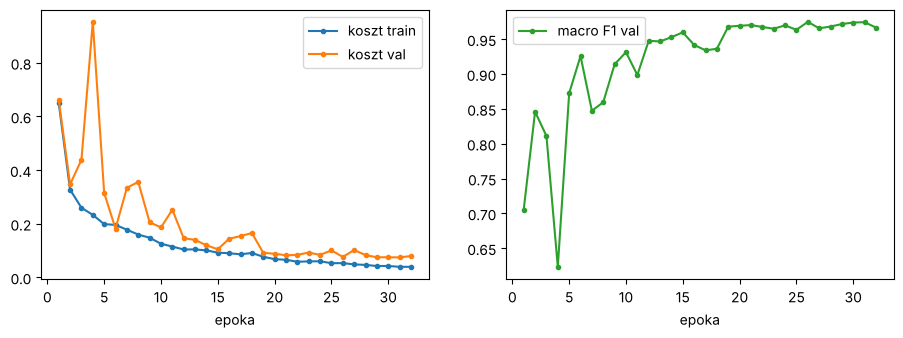

In [7]:
# B2. Trening z walidacją: najlepsza epoka i wczesne zatrzymanie
koszt_fn = nn.CrossEntropyLoss()                                        # entropia krzyżowa dla wielu klas
optymalizator = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
harmonogram = torch.optim.lr_scheduler.ReduceLROnPlateau(optymalizator, mode="max", factor=0.5, patience=2)


@torch.no_grad()
def przewiduj(loader):
    model.eval()                                       # tryb oceny: bez dropoutu
    return torch.cat([model(x.to(DEVICE)).cpu() for x, _ in loader])


historia, najlepszy_f1, bez_poprawy = [], 0, 0
for epoka in range(1, 41):
    model.train()                                      # tryb treningu
    suma = 0
    for x, y in train_loader:
        x, y = augmentacja(x).to(DEVICE), y.to(DEVICE)
        optymalizator.zero_grad()
        koszt = koszt_fn(model(x), y)
        koszt.backward()                               # gradienty
        optymalizator.step()                           # poprawa wag
        suma += koszt.item() * len(y)
    wyj_val = przewiduj(val_loader)
    f1_val = f1_score(etykiety["val"], wyj_val.argmax(1), average="macro")
    harmonogram.step(f1_val)                           # mniejszy krok, gdy walidacja przestaje rosnąć
    historia.append({"epoka": epoka, "koszt train": suma / len(zbior["train"]),
                     "koszt val": koszt_fn(wyj_val, torch.tensor(etykiety["val"])).item(), "macro F1 val": f1_val})
    print({k: round(v, 4) for k, v in historia[-1].items()})
    if f1_val > najlepszy_f1:                          # zapamiętaj wagi najlepszej epoki
        najlepszy_f1, najlepsza_epoka, wagi, bez_poprawy = f1_val, epoka, copy.deepcopy(model.state_dict()), 0
    else:
        bez_poprawy += 1
        if bez_poprawy == 6:                           # 6 epok bez poprawy: koniec
            break
model.load_state_dict(wagi)
print(f"najlepsza epoka {najlepsza_epoka}, macro F1 na walidacji {najlepszy_f1:.4f}")

pd.DataFrame(historia).set_index("epoka").plot(subplots=[("koszt train", "koszt val"), ("macro F1 val",)],
                                               figsize=(11, 3.5), layout=(1, 2), marker=".")
plt.show()

### Wnioski z części B
- **Architektura:** trzy bloki po dwie konwolucje 3 x 3 z normalizacją batcha i ReLU, między
  blokami zmniejszanie obrazu (28, 14, 7 pikseli), potem średnia z każdej mapy cech, dropout 30%
  i warstwa liniowa na 8 klas. Razem 288 936 parametrów, wystarczająco na małe obrazy.
- **Funkcja kosztu:** entropia krzyżowa. **Optymalizator:** AdamW (krok 0,001, lekka kara za duże
  wagi), paczki po 128 obrazów. Krok zmniejsza się o połowę, gdy wynik na walidacji przestaje rosnąć.
- **Walidacja:** po każdej epoce macro F1 na walidacji. Zapamiętuję wagi najlepszej epoki, a po 6
  epokach bez poprawy kończę trening. Najlepsza była epoka 26 (macro F1 na walidacji 0,975),
  trening skończył się po 32 epokach.
- **Krzywe:** na początku wynik na walidacji mocno skacze (w epoce 4 macro F1 spada do 0,62),
  po zmniejszeniu kroku uczenia krzywe się uspokajają. Koszt na train i val jest podobny
  (0,053 i 0,077 w najlepszej epoce), więc model nie jest wyraźnie przeuczony.
- Zbiór testowy nie był używany w tej części.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

accuracy 0.9673 | balanced accuracy 0.9610 | macro F1 0.9636
                      precision    recall  f1-score   support

             bazofil      0.975     0.947     0.960       244
           eozynofil      0.994     1.000     0.997       624
         erytroblast      0.977     0.968     0.973       311
niedojrz. granulocyt      0.904     0.945     0.924       579
            limfocyt      0.947     0.951     0.949       243
             monocyt      0.955     0.905     0.929       284
           neutrofil      0.985     0.973     0.979       666
         płytka krwi      0.996     1.000     0.998       470

            accuracy                          0.967      3421
           macro avg      0.967     0.961     0.964      3421
        weighted avg      0.968     0.967     0.967      3421

accuracy bez obrazów skopiowanych z train: 0.9675


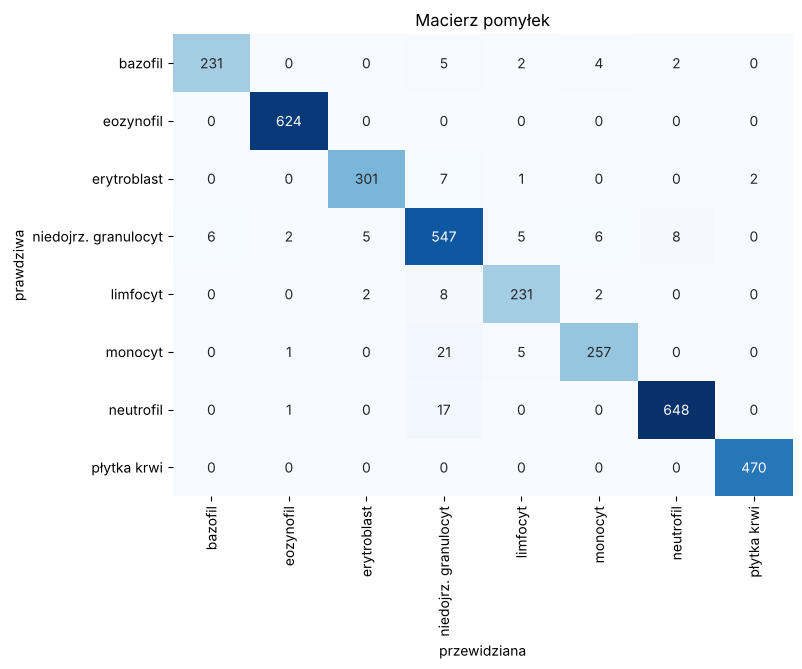

In [8]:
# C1. Ocena na teście (jedyne użycie zbioru testowego) i analiza pomyłek
y_test = etykiety["test"]
pred = przewiduj(test_loader).argmax(1).numpy()
print(f"accuracy {accuracy_score(y_test, pred):.4f} | balanced accuracy {balanced_accuracy_score(y_test, pred):.4f} | "
      f"macro F1 {f1_score(y_test, pred, average='macro'):.4f}")
print(classification_report(y_test, pred, target_names=KLASY, digits=3))
bez_kopii = ~np.isin(hashe["test"], hashe["train"])           # testowe obrazy bez identycznej kopii w train
print(f"accuracy bez obrazów skopiowanych z train: {accuracy_score(y_test[bez_kopii], pred[bez_kopii]):.4f}")

macierz = confusion_matrix(y_test, pred)
plt.figure(figsize=(8, 6))
sns.heatmap(macierz, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=KLASY, yticklabels=KLASY)
plt.xlabel("przewidziana"); plt.ylabel("prawdziwa"); plt.title("Macierz pomyłek")
plt.show()

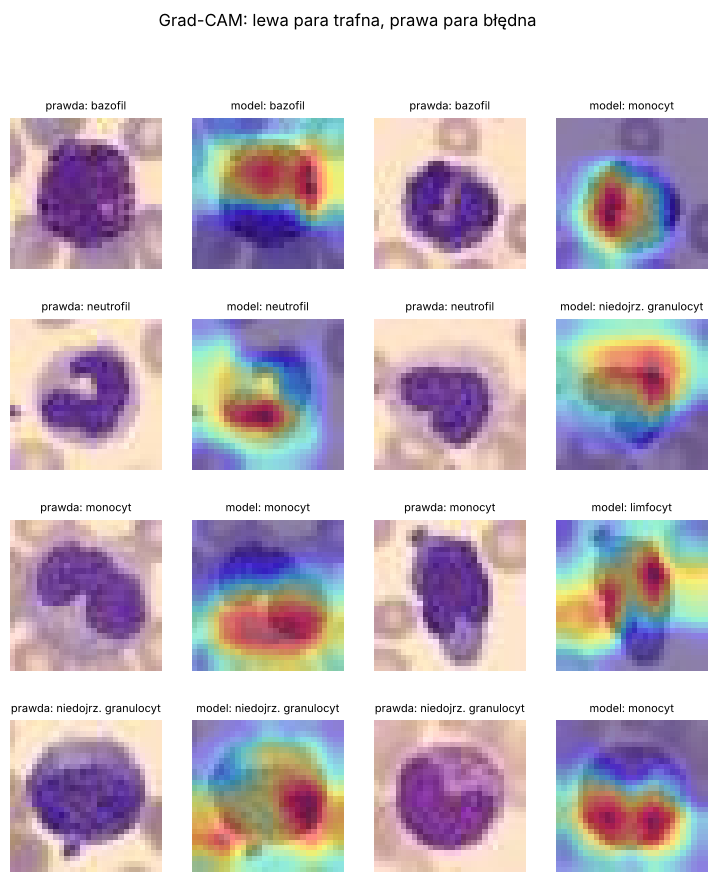

In [9]:
# C2. Grad-CAM: który fragment obrazu przekonał sieć (Selvaraju i in., 2017)
# 1. bierzemy 128 map cech 7 x 7 z ostatniego bloku, 2. gradient wyniku klasy względem każdej mapy
# mówi, jak bardzo jest ważna, 3. sumujemy mapy razy ich ważność i zostawiamy wartości dodatnie.
def grad_cam(i, klasa):
    model.eval()
    mapy = cechy(zbior["test"][i][0][None].to(DEVICE))           # (1, 128, 7, 7)
    grad = torch.autograd.grad(glowa(mapy)[0, klasa], mapy)[0]
    cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * mapy).sum(1, keepdim=True))
    return F.interpolate(cam, size=28, mode="bilinear")[0, 0].detach().cpu()   # powiększenie do 28 x 28


# Dla 4 klas z największą liczbą błędów: jeden trafny i jeden błędny przykład.
klasy = np.argsort(macierz.sum(1) - macierz.diagonal())[-4:]
fig, axes = plt.subplots(4, 4, figsize=(9, 10))
for w, k in enumerate(klasy):
    trafny = np.where((y_test == k) & (pred == k))[0][0]
    bledny = np.where((y_test == k) & (pred != k))[0][0]
    for kol, i in enumerate([trafny, bledny]):
        axes[w, 2 * kol].imshow(obrazy["test"][i])
        axes[w, 2 * kol].set_title(f"prawda: {KLASY[k]}", fontsize=8)
        axes[w, 2 * kol + 1].imshow(obrazy["test"][i])
        axes[w, 2 * kol + 1].imshow(grad_cam(i, pred[i]), cmap="jet", alpha=0.45)
        axes[w, 2 * kol + 1].set_title(f"model: {KLASY[pred[i]]}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Grad-CAM: lewa para trafna, prawa para błędna")
plt.show()

### Wnioski z części C
- **Test:** accuracy 96,7%, balanced accuracy 96,1%, macro F1 0,964. Wynik na walidacji był
  podobny, więc wybór epoki nie dopasował się nadmiernie do walidacji.
- **Klasy:** najłatwiejsze są płytki krwi i eozynofile (F1 0,998 i 0,997), najtrudniejsze niedojrzałe
  granulocyty (0,924) i monocyty (0,929).
- **Pomyłki:** większość błędów to komórki uznane za niedojrzały granulocyt: monocyty (21 razy),
  neutrofile (17), limfocyty (8) i erytroblasty (7). Ma to sens biologiczny: niedojrzałe granulocyty
  to etapy dojrzewania o wyglądzie pośrednim, a na obrazie 28 x 28 nie widać ziarnistości.
- **Kopie z train:** bez 5 testowych obrazów skopiowanych z train accuracy wynosi 96,75% zamiast
  96,73%, więc duplikaty nie zawyżają wyniku.
- **Grad-CAM:** przy trafnych predykcjach mapa skupia się na jądrze komórki, którego kształt odróżnia
  typy. Przy pomyłkach obejmuje często całą komórkę albo jej brzeg i tło, czyli model opiera się
  na ogólnej wielkości i kształcie zamiast na szczegółach jądra.
- **Ograniczenia Grad-CAM:** mapa ma tylko 7 x 7 pól, więc jest rozmyta; pokazuje, gdzie model
  patrzy, ale nie co tam widzi; zależy od wybranej warstwy; nie ma gwarancji, że wiernie oddaje
  rozumowanie modelu (Adebayo i in., 2018); 8 przykładów to ilustracja, nie dowód.
- **Co można poprawić:** obrazy w wyższej rozdzielczości (MedMNIST ma też 64 x 64 i większe),
  wagi klas w funkcji kosztu albo sieć wstępnie wytrenowana.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

**Źródła:**
- J. Yang i in., "MedMNIST v2", Scientific Data, 2023 (https://arxiv.org/abs/2110.14795), opis zbioru.
- A. Acevedo i in., "A dataset of microscopic peripheral blood cell images for development of automatic
  recognition systems", Data in Brief, 2020, źródłowe zdjęcia.
- R. R. Selvaraju i in., "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based
  Localization", ICCV 2017 (https://arxiv.org/abs/1610.02391).
- J. Adebayo i in., "Sanity Checks for Saliency Maps", NeurIPS 2018
  (https://papers.nips.cc/paper/8160-sanity-checks-for-saliency-maps).
- dokumentacja PyTorch.

**Narzędzia AI:** Claude (Anthropic), pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.